In [7]:
import numpy
import pandas
import matplotlib
import scipy

print("All libraries installed successfully!")

All libraries installed successfully!


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage
from pathlib import Path


csv_path = Path("thermal_frame_degC.csv")

thermal_data = pd.read_csv(csv_path, header=None)


T = thermal_data.to_numpy(dtype=float)


print("Thermal dataset loaded successfully!")
print("Dataset shape:", T.shape)
print("Total number of pixels:", T.size)
print("Minimum temperature:", T.min(), "°C")
print("Maximum temperature:", T.max(), "°C")

Thermal dataset loaded successfully!
Dataset shape: (120, 160)
Total number of pixels: 19200
Minimum temperature: -12.73 °C
Maximum temperature: 117.49 °C


In [9]:
max_temp = np.max(T)
max_location = np.unravel_index(np.argmax(T), T.shape)

row, col = max_location

print("Maximum Temperature Analysis")
print(f"Maximum temperature: {max_temp:.2f} °C")
print(f"Pixel location (row, column): ({row}, {col})")
print(f"Pixel location (1-based): ({row + 1}, {col + 1})")

Maximum Temperature Analysis
Maximum temperature: 117.49 °C
Pixel location (row, column): (62, 45)
Pixel location (1-based): (63, 46)


In [11]:
percentiles = [50, 90, 95, 99]

print("Temperature Distribution")

for p in percentiles:
    value = np.percentile(T, p)
    print(f"{p}th percentile: {value:.2f} °C")

threshold = 75.0

hot_pixel_count = np.sum(T >= threshold)
hot_pixel_percentage = (hot_pixel_count / T.size) * 100

print("\nCandidate Hotspot Threshold")
print(f"Threshold: {threshold:.2f} °C")
print(f"Pixels at or above threshold: {hot_pixel_count}")
print(f"Percentage of total pixels: {hot_pixel_percentage:.2f}%")

Temperature Distribution
50th percentile: 34.10 °C
90th percentile: 69.69 °C
95th percentile: 70.56 °C
99th percentile: 72.12 °C

Candidate Hotspot Threshold
Threshold: 75.00 °C
Pixels at or above threshold: 146
Percentage of total pixels: 0.76%


In [12]:
# Compare hotspot detection at different thresholds

for threshold_value in [73, 74, 75, 76, 80]:
    hot_mask = T >= threshold_value

    # Identify connected hotspot regions (8-connectivity)
    structure = np.ones((3, 3), dtype=int)
    labels, num_regions = ndimage.label(
        hot_mask, structure=structure
    )

    print(
        f"Threshold: {threshold_value}°C | "
        f"Hot pixels: {np.sum(hot_mask)} | "
        f"Connected regions: {num_regions}"
    )

Threshold: 73°C | Hot pixels: 178 | Connected regions: 2
Threshold: 74°C | Hot pixels: 159 | Connected regions: 2
Threshold: 75°C | Hot pixels: 146 | Connected regions: 2
Threshold: 76°C | Hot pixels: 129 | Connected regions: 2
Threshold: 80°C | Hot pixels: 97 | Connected regions: 2


In [13]:
for threshold_value in [73, 74, 75, 76, 80]:

    hot_mask = T >= threshold_value

    structure = np.ones((3, 3), dtype=int)
    labels, num_regions = ndimage.label(
        hot_mask, structure=structure
    )

    region_sizes = np.bincount(labels.ravel())[1:]
    region_sizes = sorted(region_sizes, reverse=True)

    print(f"\nThreshold: {threshold_value}°C")

    for i, size in enumerate(region_sizes, start=1):
        print(f"  Hotspot {i}: {size} pixels")


Threshold: 73°C
  Hotspot 1: 120 pixels
  Hotspot 2: 58 pixels

Threshold: 74°C
  Hotspot 1: 114 pixels
  Hotspot 2: 45 pixels

Threshold: 75°C
  Hotspot 1: 103 pixels
  Hotspot 2: 43 pixels

Threshold: 76°C
  Hotspot 1: 92 pixels
  Hotspot 2: 37 pixels

Threshold: 80°C
  Hotspot 1: 76 pixels
  Hotspot 2: 21 pixels


In [ ]:
threshold = 75.0
hot_mask = T >= threshold
structure = np.ones((3, 3), dtype=int)
labels, num_hotspots = ndimage.label(
    hot_mask, structure=structure
)

print("Hotspot Detection Results")
print("Detection threshold:", threshold, "°C")
print("Number of hotspots:", num_hotspots)

for region_id in range(1, num_hotspots + 1):

    region_mask = labels == region_id
    coordinates = np.argwhere(region_mask)

    min_row, min_col = coordinates.min(axis=0)
    max_row, max_col = coordinates.max(axis=0)

    hotspot_temps = T[region_mask]

    print(f"\nHotspot {region_id}")
    print("Pixel count:", len(coordinates))
    print(f"Peak temperature: {hotspot_temps.max():.2f} °C")
    print(f"Mean temperature: {hotspot_temps.mean():.2f} °C")
    print(
        f"Bounding box: Rows {min_row}-{max_row}, "
        f"Columns {min_col}-{max_col}"
    )

Hotspot Detection Results
Detection threshold: 75.0 °C
Number of hotspots: 2

Hotspot 1
Pixel count: 103
Peak temperature: 117.49 °C
Mean temperature: 89.75 °C
Bounding box: Rows 56-68, Columns 40-50

Hotspot 2
Pixel count: 43
Peak temperature: 94.41 °C
Mean temperature: 81.96 °C
Bounding box: Rows 92-98, Columns 117-123


In [17]:
asset_A = T[30:113, 28:63]
asset_B = T[30:113, 98:133]

mean_A = np.mean(asset_A)
mean_B = np.mean(asset_B)

mean_difference = abs(mean_A - mean_B)

print("Asset Temperature Comparison")
print(f"Asset A mean temperature: {mean_A:.2f} °C")
print(f"Asset B mean temperature: {mean_B:.2f} °C")
print(f"Absolute mean temperature difference: {mean_difference:.2f} °C")

Asset Temperature Comparison
Asset A mean temperature: 69.36 °C
Asset B mean temperature: 69.17 °C
Absolute mean temperature difference: 0.19 °C


In [18]:
COLUMN_OFFSET = 70

print("HOTSPOT DELTA-T ANALYSIS")

for region_id in range(1, num_hotspots + 1):

    region_mask = labels == region_id
    coordinates = np.argwhere(region_mask)
    temperatures = T[region_mask]

    
    peak_index = np.argmax(temperatures)
    peak_row, peak_col = coordinates[peak_index]
    peak_temp = temperatures[peak_index]

   
    if 28 <= peak_col <= 62:
        asset_name = "Asset A"
        counterpart_col = peak_col + COLUMN_OFFSET

    else:
        asset_name = "Asset B"
        counterpart_col = peak_col - COLUMN_OFFSET

    counterpart_temp = T[peak_row, counterpart_col]

    
    delta_t = peak_temp - counterpart_temp

    
    if delta_t < 10:
        classification = "Normal"
    elif delta_t <= 25:
        classification = "Watch"
    else:
        classification = "Warning"

    print(f"\nHotspot {region_id} ({asset_name})")
    print(f"Peak location: ({peak_row}, {peak_col})")
    print(f"Peak temperature: {peak_temp:.2f} °C")
    print(
        f"Corresponding pixel: "
        f"({peak_row}, {counterpart_col})"
    )
    print(f"Corresponding temperature: {counterpart_temp:.2f} °C")
    print(f"Delta-T: {delta_t:.2f} °C")
    print(f"Classification: {classification}")

HOTSPOT DELTA-T ANALYSIS

Hotspot 1 (Asset A)
Peak location: (62, 45)
Peak temperature: 117.49 °C
Corresponding pixel: (62, 115)
Corresponding temperature: 68.18 °C
Delta-T: 49.31 °C
Classification: Warning

Hotspot 2 (Asset B)
Peak location: (95, 120)
Peak temperature: 94.41 °C
Corresponding pixel: (95, 50)
Corresponding temperature: 69.74 °C
Delta-T: 24.67 °C
Classification: Watch


C:\Users\rssto\AppData\Local\Temp\ipykernel_35568\3907770692.py:38: UserWarning: You passed an edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


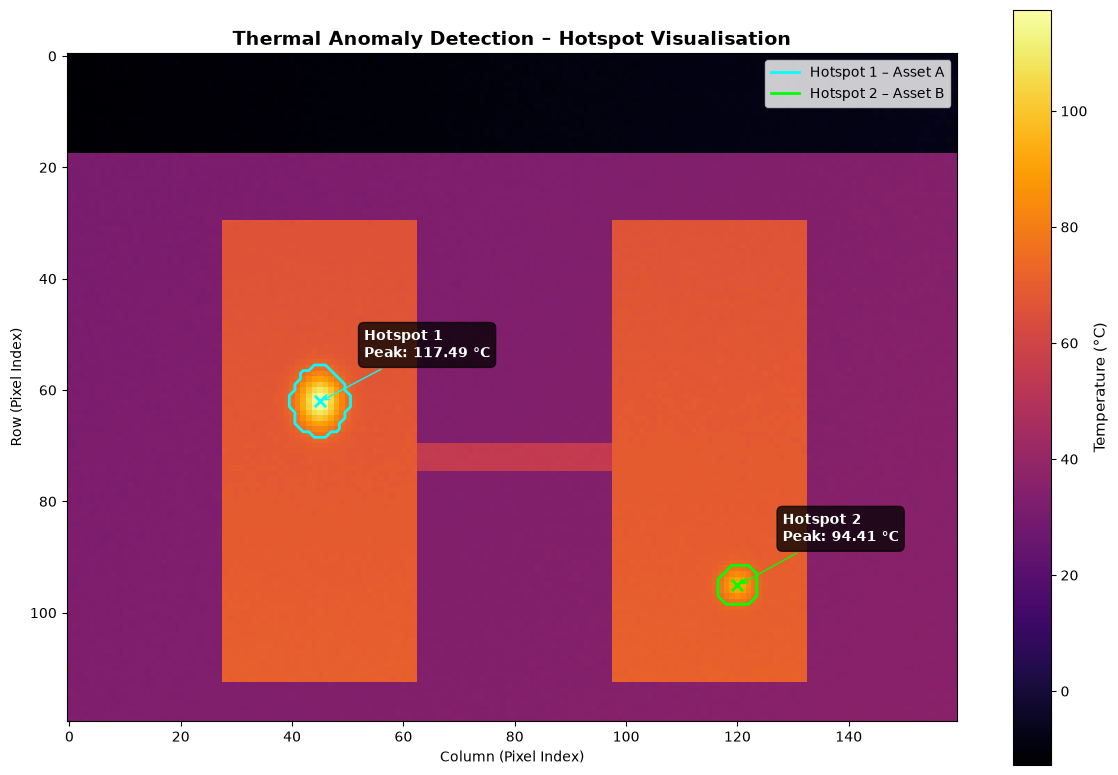

Figure saved successfully: C:\Users\rssto\Downloads\Task_Thermal_AI\Task_Thermal_AI\thermal_hotspots.png


In [19]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(12, 8))

heatmap = ax.imshow(
    T,
    cmap="inferno",
    origin="upper",
    interpolation="nearest",
    aspect="equal"
)

cbar = fig.colorbar(heatmap, ax=ax)
cbar.set_label("Temperature (°C)", fontsize=11)

hotspot_colors = ["cyan", "lime"]

for region_id in range(1, num_hotspots + 1):

    region_mask = labels == region_id
    coordinates = np.argwhere(region_mask)

    temperatures = T[region_mask]
    peak_index = np.argmax(temperatures)
    peak_row, peak_col = coordinates[peak_index]
    peak_temp = temperatures[peak_index]

    color = hotspot_colors[region_id - 1]

    ax.contour(
        region_mask.astype(int),
        levels=[0.5],
        colors=[color],
        linewidths=2
    )

    
    ax.scatter(
        peak_col,
        peak_row,
        color=color,
        edgecolors="white",
        s=65,
        marker="x",
        linewidths=2
    )

   
    center_row, center_col = coordinates.mean(axis=0)

    ax.annotate(
        f"Hotspot {region_id}\nPeak: {peak_temp:.2f} °C",
        xy=(center_col, center_row),
        xytext=(center_col + 8, center_row - 8),
        color="white",
        fontsize=10,
        fontweight="bold",
        arrowprops=dict(arrowstyle="->", color=color),
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="black",
            alpha=0.75
        )
    )


ax.set_title(
    "Thermal Anomaly Detection – Hotspot Visualisation",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Column (Pixel Index)")
ax.set_ylabel("Row (Pixel Index)")

ax.legend(
    handles=[
        Line2D([0], [0], color="cyan", lw=2, label="Hotspot 1 – Asset A"),
        Line2D([0], [0], color="lime", lw=2, label="Hotspot 2 – Asset B")
    ],
    loc="upper right"
)

plt.tight_layout()


output_path = Path("thermal_hotspots.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Figure saved successfully: {output_path.resolve()}")

In [20]:
print("Current notebook folder:", Path.cwd())
print("Image saved:", output_path.exists())

if output_path.exists():
    print("File size:", round(output_path.stat().st_size / 1024, 2), "KB")

Current notebook folder: c:\Users\rssto\Downloads\Task_Thermal_AI\Task_Thermal_AI
Image saved: True
File size: 199.57 KB


In [21]:
results = []

for region_id in range(1, num_hotspots + 1):
    region_mask = labels == region_id
    coordinates = np.argwhere(region_mask)
    temperatures = T[region_mask]

    peak_index = np.argmax(temperatures)
    peak_row, peak_col = coordinates[peak_index]
    peak_temp = temperatures[peak_index]

    if peak_col < 80:
        corresponding_col = peak_col + 70
        asset_name = "Asset A"
        comparison_asset = "Asset B"
    else:
        corresponding_col = peak_col - 70
        asset_name = "Asset B"
        comparison_asset = "Asset A"

    comparison_temp = T[peak_row, corresponding_col]
    delta_T = abs(peak_temp - comparison_temp)

    if delta_T < 10:
        status = "Normal"
    elif delta_T <= 25:
        status = "Watch"
    else:
        status = "Warning"

    results.append({
        "Hotspot": f"Hotspot {region_id}",
        "Asset": asset_name,
        "Peak Temperature (°C)": peak_temp,
        "Mean Temperature (°C)": temperatures.mean(),
        "Pixel Count": len(coordinates),
        "Peak Location (Row, Col)": f"({peak_row}, {peak_col})",
        "Comparison Asset": comparison_asset,
        "Comparison Temperature (°C)": comparison_temp,
        "Delta-T (°C)": delta_T,
        "Status": status
    })

results_df = pd.DataFrame(results)

display(results_df.round(2))

,Hotspot,Asset,Peak Temperature (°C),Mean Temperature (°C),Pixel Count,"Peak Location (Row, Col)",Comparison Asset,Comparison Temperature (°C),Delta-T (°C),Status
0,Hotspot 1,Asset A,117.49,89.75,103,"(62, 45)",Asset B,68.18,49.31,Warning
1,Hotspot 2,Asset B,94.41,81.96,43,"(95, 120)",Asset A,69.74,24.67,Watch
